# Stock data EDA â€” steps 1â€“4

Read-only exploration of raw OHLCV files: configure paths, inventory stocks, examine missing values and shared date coverage, and visualize selected stocks. No cleaning, filling, indicators, resampling of saved data, or final dataset export is performed here.

The shared daily index is the union of dates actually observed in the selected universe. It is **not an exchange calendar**. Missing dates outside a stock's observed history are distinguished from missing dates within its history. Full timestamp unions are optional because the source files are large.

The session-coverage section below filters working data to regular trading hours and ranks missing minutes. Raw CSVs are preserved.


## Active stock universe

Future runs exclude **IRFC, HDFCLIFE, and SBILIFE** because of their high missing-minute counts. This leaves **97 stocks**; their raw CSVs are preserved.

**Saved outputs below are the original 100-stock audit, before this exclusion.** Run all cells to refresh the EDA reports for the 97-stock universe. The calendar and union coverage will be recomputed from the retained stocks.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Works when launched from either BTP or BTP/full_predictor.
BASE_DIR = Path.cwd() if (Path.cwd() / 'datasets').is_dir() else Path.cwd() / 'full_predictor'
INPUT_DIR = BASE_DIR / 'datasets' / 'NIFTY50'
OUTPUT_DIR = BASE_DIR / 'eda_outputs'  # EDA reports only, not cleaned datasets.
SELECTED_STOCKS = None  # None = all eligible files; otherwise e.g. ['RELIANCE', 'TCS'].
EXCLUDED_STOCKS = {'IRFC', 'HDFCLIFE', 'SBILIFE'}
PLOT_STOCK = 'RELIANCE'
USE_GPU = True
BUILD_COMMON_TIMESTAMP_INDEX = False  # Daily comparison below always runs.
SAVE_EDA_REPORTS = True

if not INPUT_DIR.is_dir():
    raise FileNotFoundError(f'Input directory does not exist: {INPUT_DIR.resolve()}')
files = [p for p in sorted(INPUT_DIR.glob('*.csv')) if p.stem not in EXCLUDED_STOCKS]
if SELECTED_STOCKS is not None:
    requested = set(SELECTED_STOCKS)
    files = [p for p in files if p.stem in requested]
    missing = requested - {p.stem for p in files}
    if missing:
        raise ValueError(f'Stocks not found: {sorted(missing)}')
if not files:
    raise ValueError('No input CSV files found.')
input_filepaths = {p.stem: p.resolve() for p in files}
output_filepaths = {name: OUTPUT_DIR / name for name in [
    'inventory.csv', 'column_quality.csv', 'daily_row_counts.csv',
    'missing_days.csv', 'coverage_summary.csv', 'eda_config.json']}
print(f'Input: {INPUT_DIR.resolve()}')
print(f'Output: {OUTPUT_DIR.resolve()}')
print(f'{len(files)} files; {sum(p.stat().st_size for p in files) / 1e9:.2f} GB')
display(pd.DataFrame({'stock': list(input_filepaths), 'input_filepath': list(input_filepaths.values())}))
display(pd.DataFrame({'report': list(output_filepaths), 'output_filepath': list(output_filepaths.values())}))


Input: C:\Users\xprin\Desktop\AIML\BTP\full_predictor\datasets\NIFTY50
Output: C:\Users\xprin\Desktop\AIML\BTP\full_predictor\eda_outputs
97 files; 4.52 GB


,stock,input_filepath
0,ABB,C:\Users\xprin\Desktop\AIML\BTP\full_predictor...
1,ADANIENSOL,C:\Users\xprin\Desktop\AIML\BTP\full_predictor...
2,ADANIENT,C:\Users\xprin\Desktop\AIML\BTP\full_predictor...
3,ADANIGREEN,C:\Users\xprin\Desktop\AIML\BTP\full_predictor...
4,ADANIPORTS,C:\Users\xprin\Desktop\AIML\BTP\full_predictor...
...,...,...
92,UNITDSPR,C:\Users\xprin\Desktop\AIML\BTP\full_predictor...
93,VBL,C:\Users\xprin\Desktop\AIML\BTP\full_predictor...
94,VEDL,C:\Users\xprin\Desktop\AIML\BTP\full_predictor...
95,WIPRO,C:\Users\xprin\Desktop\AIML\BTP\full_predictor...


,report,output_filepath
0,inventory.csv,c:\Users\xprin\Desktop\AIML\BTP\full_predictor...
1,column_quality.csv,c:\Users\xprin\Desktop\AIML\BTP\full_predictor...
2,daily_row_counts.csv,c:\Users\xprin\Desktop\AIML\BTP\full_predictor...
3,missing_days.csv,c:\Users\xprin\Desktop\AIML\BTP\full_predictor...
4,coverage_summary.csv,c:\Users\xprin\Desktop\AIML\BTP\full_predictor...
5,eda_config.json,c:\Users\xprin\Desktop\AIML\BTP\full_predictor...


## GPU availability

CSV parsing, datetime operations, and pandas joins run on CPU. When CUDA-enabled PyTorch and a compatible GPU are available, finite numeric values are transferred one stock at a time for summary reductions. Small reductions may be faster on CPU; GPU use is optional. A CPU fallback keeps the notebook runnable without CUDA. No packages are installed by this notebook.

Validated environment: NVIDIA RTX 3060 is present, but the workspace currently has CPU-only PyTorch (`2.14.0+cpu`), so this saved run used CPU.


In [2]:
try:
    import torch
except ImportError:
    torch = None
GPU_AVAILABLE = torch is not None and torch.cuda.is_available()
DEVICE = 'cuda' if USE_GPU and GPU_AVAILABLE else 'cpu'
print('Numeric summary backend:', DEVICE)
if DEVICE == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('CUDA unavailable or disabled; pandas/NumPy CPU fallback is active.')

def numeric_summary(values):
    values = np.asarray(values, dtype=np.float64)
    values = values[np.isfinite(values)]
    if not len(values):
        return dict(mean=np.nan, std=np.nan, minimum=np.nan, maximum=np.nan)
    if DEVICE == 'cuda':
        tensor = torch.as_tensor(values, dtype=torch.float64, device='cuda')
        result = dict(mean=tensor.mean().item(), std=tensor.std(unbiased=False).item(),
                      minimum=tensor.min().item(), maximum=tensor.max().item())
        del tensor
        return result
    return dict(mean=float(values.mean()), std=float(values.std()),
                minimum=float(values.min()), maximum=float(values.max()))


Numeric summary backend: cuda
GPU: NVIDIA GeForce RTX 3060


## 2. Inventory and raw quality checks

Each file is read separately. Counts describe the original rows; temporary numeric/date conversions are used only to inspect quality. No source file is modified. OHLC inconsistencies and extreme returns are flags for review, not deletion rules. Timestamps are treated as naive wall-clock values; no timezone or trading-session filter is assumed.


In [3]:
PRICE_COLUMNS = ['open', 'high', 'low', 'close']
NUMERIC_COLUMNS = PRICE_COLUMNS + ['volume']
REQUIRED_COLUMNS = ['date'] + NUMERIC_COLUMNS
inventory_rows, quality_rows, daily_counts = [], [], {}
common_datetime_index = pd.DatetimeIndex([])

for position, path in enumerate(files, 1):
    raw = pd.read_csv(path)
    absent = set(REQUIRED_COLUMNS) - set(raw.columns)
    if absent:
        raise ValueError(f'{path.name}: missing required columns {sorted(absent)}')
    dates = pd.to_datetime(raw['date'], errors='coerce')
    numeric = raw[NUMERIC_COLUMNS].apply(pd.to_numeric, errors='coerce')
    valid_dates = dates.dropna()
    unique_dates = pd.DatetimeIndex(valid_dates.unique()).sort_values()
    deltas = pd.Series(unique_dates).diff().dt.total_seconds().div(60)
    same_day = pd.Series(unique_dates).dt.normalize().eq(pd.Series(unique_dates).shift().dt.normalize())
    daily_counts[path.stem] = valid_dates.dt.normalize().value_counts().sort_index()
    if BUILD_COMMON_TIMESTAMP_INDEX:
        common_datetime_index = common_datetime_index.union(unique_dates)
    prices = numeric[PRICE_COLUMNS]
    finite_prices = pd.Series(np.isfinite(prices.to_numpy()).all(axis=1), index=raw.index)
    bad_ohlc = finite_prices & (
        (numeric['high'] < prices[['open', 'close', 'low']].max(axis=1)) |
        (numeric['low'] > prices[['open', 'close', 'high']].min(axis=1)))
    duplicate_dates = valid_dates.duplicated(keep=False)
    duplicate_rows = raw.duplicated()
    timestamp_groups = raw.loc[dates.notna(), NUMERIC_COLUMNS].copy()
    timestamp_groups.index = pd.DatetimeIndex(valid_dates)
    duplicated_groups = timestamp_groups.loc[timestamp_groups.index.duplicated(keep=False)]
    conflicts = (duplicated_groups.groupby(level=0).nunique(dropna=False).gt(1).any(axis=1).sum()
                 if len(duplicated_groups) else 0)
    inventory_rows.append(dict(
        stock=path.stem, rows=len(raw), size_mb=path.stat().st_size / 1e6,
        first_timestamp=valid_dates.min(), last_timestamp=valid_dates.max(),
        observed_days=valid_dates.dt.normalize().nunique(), raw_nan_count=int(raw.isna().sum().sum()),
        invalid_timestamps=int(dates.isna().sum()),
        exact_duplicate_rows=int(duplicate_rows.sum()),
        duplicate_timestamp_rows=int(duplicate_dates.sum()), conflicting_timestamps=int(conflicts),
        sorted_timestamps=valid_dates.is_monotonic_increasing,
        invalid_ohlc_rows=int(bad_ohlc.sum()),
        nonpositive_price_rows=int((prices <= 0).any(axis=1).sum()),
        negative_volume_rows=int((numeric['volume'] < 0).sum()),
        zero_volume_rows=int((numeric['volume'] == 0).sum()),
        median_interval_minutes=float(deltas.median()),
        within_day_gaps_over_1min=int(((deltas > 1) & same_day).sum())))
    for col in NUMERIC_COLUMNS:
        values = numeric[col].to_numpy(dtype=float)
        quality_rows.append(dict(stock=path.stem, column=col, raw_dtype=str(raw[col].dtype),
            raw_nan=int(raw[col].isna().sum()),
            conversion_failures=int((raw[col].notna() & numeric[col].isna()).sum()),
            infinity_count=int(np.isinf(values).sum()), **numeric_summary(values)))
    if position % 10 == 0 or position == len(files):
        print(f'Inspected {position}/{len(files)} stocks')
    del raw, numeric, prices, timestamp_groups, duplicated_groups

inventory = pd.DataFrame(inventory_rows).set_index('stock').sort_index()
column_quality = pd.DataFrame(quality_rows)
display(inventory)
display(column_quality)
print('Total raw missing values:', inventory['raw_nan_count'].sum())
print('Numeric conversion failures:', column_quality['conversion_failures'].sum())


Inspected 10/97 stocks
Inspected 20/97 stocks
Inspected 30/97 stocks
Inspected 40/97 stocks
Inspected 50/97 stocks
Inspected 60/97 stocks
Inspected 70/97 stocks
Inspected 80/97 stocks
Inspected 90/97 stocks
Inspected 97/97 stocks


,rows,size_mb,first_timestamp,last_timestamp,observed_days,raw_nan_count,invalid_timestamps,exact_duplicate_rows,duplicate_timestamp_rows,conflicting_timestamps,sorted_timestamps,invalid_ohlc_rows,nonpositive_price_rows,negative_volume_rows,zero_volume_rows,median_interval_minutes,within_day_gaps_over_1min
stock,,,,,,,,,,,,,,,,,
ABB,970889,50.714262,2015-02-02 09:15:00,2025-08-06 17:57:00,2605,0,0,0,0,0,True,0,0,0,75557,1.0,1553
ADANIENSOL,919752,46.146921,2015-07-31 09:50:00,2025-08-06 18:13:00,2481,0,0,0,0,0,True,0,0,0,65544,1.0,4882
ADANIENT,972518,50.321882,2015-02-02 09:15:00,2025-08-06 17:57:00,2605,0,0,0,0,0,True,0,0,0,2296,1.0,99
ADANIGREEN,659285,33.778173,2018-06-18 09:44:00,2025-08-06 18:13:00,1770,0,0,0,0,0,True,0,0,0,19998,1.0,1255
ADANIPORTS,972581,50.156974,2015-02-02 09:15:00,2025-08-06 18:13:00,2605,0,0,0,0,0,True,0,0,0,124,1.0,98
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
UNITDSPR,972568,50.022511,2015-02-02 09:15:00,2025-08-06 20:28:00,2605,0,0,0,0,0,True,1,0,0,1638,1.0,100
VBL,806691,38.791414,2016-11-08 09:44:00,2025-08-06 20:28:00,2170,0,0,0,0,0,True,0,0,0,85451,1.0,2406
VEDL,972571,49.748920,2015-02-02 09:15:00,2025-08-06 20:28:00,2605,0,0,0,0,0,True,0,0,0,75,1.0,100


,stock,column,raw_dtype,raw_nan,conversion_failures,infinity_count,mean,std,minimum,maximum
0,ABB,open,float64,0,0,0,2352.728304,2062.287151,724.35,9149.95
1,ABB,high,float64,0,0,0,2354.118314,2063.544710,725.00,9149.95
2,ABB,low,float64,0,0,0,2351.296884,2061.007005,722.35,9113.00
3,ABB,close,float64,0,0,0,2352.716605,2062.272689,724.35,9131.60
4,ABB,volume,int64,0,0,0,550.023008,3109.886242,0.00,680838.00
...,...,...,...,...,...,...,...,...,...,...
480,ZYDUSLIFE,open,float64,0,0,0,495.721863,231.272820,206.65,2131.20
481,ZYDUSLIFE,high,float64,0,0,0,496.014966,231.383960,206.75,2131.20
482,ZYDUSLIFE,low,float64,0,0,0,495.411001,231.149760,206.50,2126.10
483,ZYDUSLIFE,close,float64,0,0,0,495.718872,231.271657,206.60,2131.20


Total raw missing values: 0
Numeric conversion failures: 0


## 3. Common datetime index and missing-stock days

`daily_row_counts` aligns every stock on the same `DatetimeIndex`: the union of observed dates. Zero means no parseable timestamp for that stock on that date. It does not prove that the date was a regular trading day. Dates absent for **all** stocks are invisible to this union and require a verified exchange calendar to classify.

`missing_within_history` identifies holes between each stock's first and last observed dates. `outside_observed_history` may reflect different listing dates or data coverage; it is not automatically bad data. Row-count heatmaps also expose partially covered days. Counts include duplicates and any off-session rows; inspect quality flags before interpreting completeness.


In [4]:
daily_row_counts = pd.concat(daily_counts, axis=1).fillna(0).astype('int32').sort_index()
daily_row_counts.index = pd.DatetimeIndex(daily_row_counts.index, name='date')
common_daily_index = daily_row_counts.index
presence = daily_row_counts.gt(0)
within_history = pd.DataFrame(False, index=common_daily_index, columns=daily_row_counts.columns)
missing_records = []
for stock in daily_row_counts:
    observed = common_daily_index[presence[stock]]
    if len(observed):
        within_history[stock] = (common_daily_index >= observed.min()) & (common_daily_index <= observed.max())
    absent_dates = common_daily_index[~presence[stock]]
    for day in absent_dates:
        missing_records.append({'date': day, 'stock': stock,
            'reason': 'missing_within_history' if within_history.at[day, stock] else 'outside_observed_history'})
missing_days = pd.DataFrame(missing_records, columns=['date', 'stock', 'reason'])
missing_within_history = within_history & ~presence
coverage_summary = pd.DataFrame({
    'observed_days': presence.sum(),
    'missing_within_history': missing_within_history.sum(),
    'outside_observed_history': (~within_history).sum(),
    'median_rows_on_observed_day': daily_row_counts.where(presence).median(),
})
coverage_summary['coverage_pct_within_history'] = 100 * presence.sum() / within_history.sum().replace(0, np.nan)
display(coverage_summary.sort_values('missing_within_history', ascending=False))
display(missing_days.head(30))
print('Common daily index:', len(common_daily_index), 'dates')
print('Full missing-day details available in missing_days and the optional report CSV.')

def stocks_missing_on(day, within_history_only=True):
    day = pd.Timestamp(day).normalize()
    if day not in common_daily_index:
        raise ValueError('Date is absent from the observed union; calendar status is unknown.')
    mask = missing_within_history.loc[day] if within_history_only else ~presence.loc[day]
    return mask.index[mask].tolist()

# Example: stocks_missing_on('2024-01-15')
if BUILD_COMMON_TIMESTAMP_INDEX:
    common_datetime_index = common_datetime_index.sort_values()
    print('Common full-resolution timestamp index:', len(common_datetime_index))
    print('Use this index selectively; a dense timestamp-by-stock data table can consume substantial memory.')


,observed_days,missing_within_history,outside_observed_history,median_rows_on_observed_day,coverage_pct_within_history
ABB,2605,0,0,375.0,100.0
ADANIENSOL,2481,0,124,375.0,100.0
ADANIENT,2605,0,0,375.0,100.0
ADANIGREEN,1770,0,835,375.0,100.0
ADANIPORTS,2605,0,0,375.0,100.0
...,...,...,...,...,...
UNITDSPR,2605,0,0,375.0,100.0
VBL,2170,0,435,375.0,100.0
VEDL,2605,0,0,375.0,100.0
WIPRO,2605,0,0,375.0,100.0


,date,stock,reason
0,2015-02-02,ADANIENSOL,outside_observed_history
1,2015-02-03,ADANIENSOL,outside_observed_history
2,2015-02-04,ADANIENSOL,outside_observed_history
3,2015-02-05,ADANIENSOL,outside_observed_history
4,2015-02-06,ADANIENSOL,outside_observed_history
5,2015-02-09,ADANIENSOL,outside_observed_history
6,2015-02-10,ADANIENSOL,outside_observed_history
7,2015-02-11,ADANIENSOL,outside_observed_history
8,2015-02-12,ADANIENSOL,outside_observed_history
9,2015-02-13,ADANIENSOL,outside_observed_history


Common daily index: 2605 dates
Full missing-day details available in missing_days and the optional report CSV.


## 4. Visual exploration

Universe plots use daily aggregates for display only. The selected-stock return calculation uses sorted, unique timestamps and positive finite closes, excludes gaps other than one minute, and does not bridge sessions. Duplicate timestamps are excluded from this diagnostic rather than resolved in the source. Large absolute returns are shown for inspection, not removed. Rolling volatility uses 30 eligible returns and is reset by date.


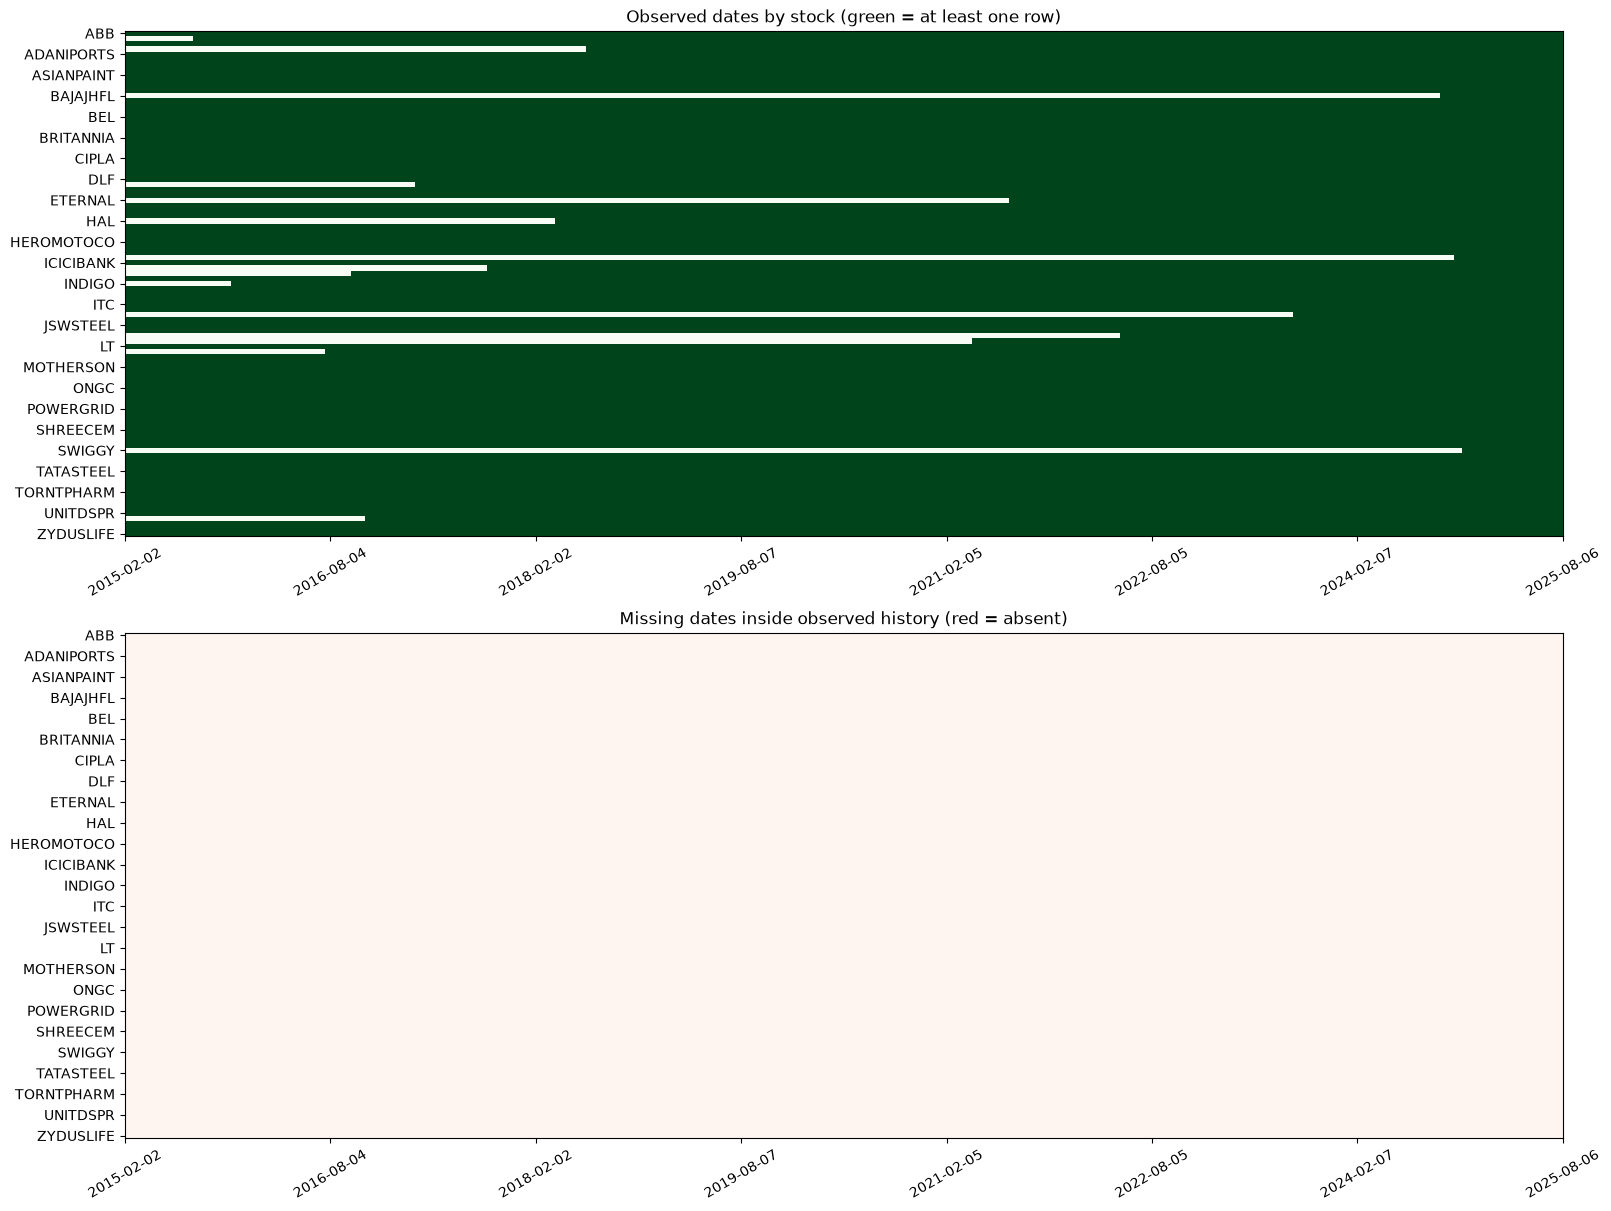

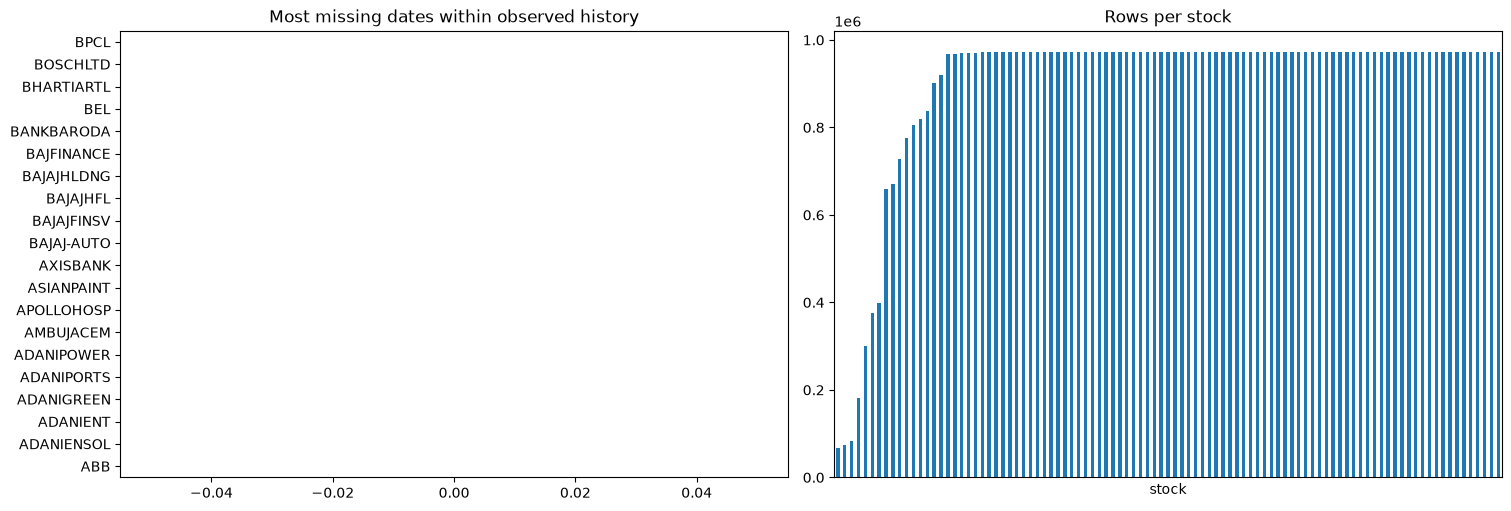

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(16, 12), constrained_layout=True)
axes[0].imshow(presence.T.to_numpy(), aspect='auto', interpolation='nearest', cmap='Greens', vmin=0, vmax=1)
axes[0].set_title('Observed dates by stock (green = at least one row)')
axes[1].imshow(missing_within_history.T.to_numpy(), aspect='auto', interpolation='nearest', cmap='Reds', vmin=0, vmax=1)
axes[1].set_title('Missing dates inside observed history (red = absent)')
for ax in axes:
    ticks = np.unique(np.linspace(0, len(common_daily_index)-1, min(8,len(common_daily_index))).astype(int))
    ax.set_xticks(ticks, [common_daily_index[i].strftime('%Y-%m-%d') for i in ticks], rotation=30)
    stock_ticks = np.arange(0, len(presence.columns), max(1,len(presence.columns)//20))
    ax.set_yticks(stock_ticks, presence.columns[stock_ticks])
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
coverage_summary['missing_within_history'].nlargest(20).sort_values().plot.barh(ax=axes[0], title='Most missing dates within observed history')
inventory['rows'].sort_values().plot.bar(ax=axes[1], title='Rows per stock', xticks=[])
plt.show()


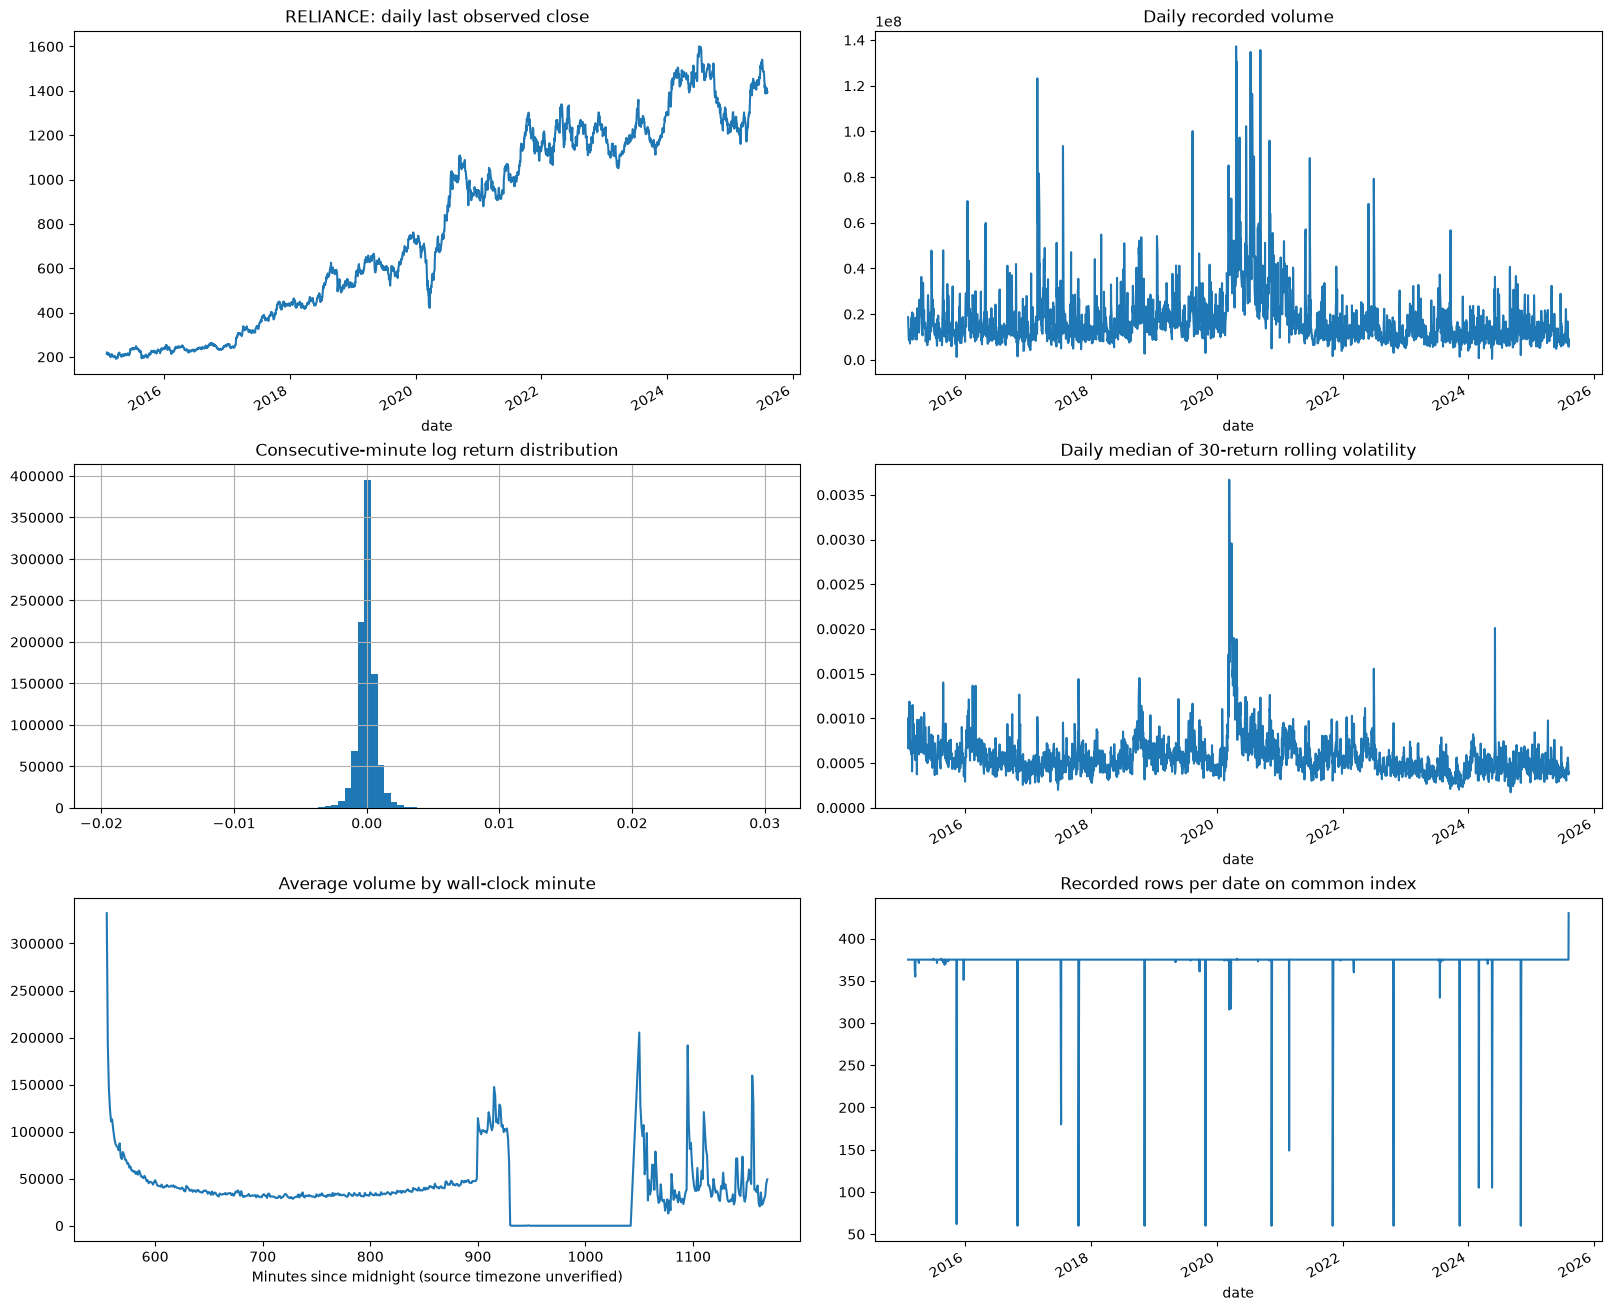

Largest absolute consecutive-minute returns:


,absolute_log_return,open,high,low,close,volume
date,,,,,,
2020-03-25 14:11:00,0.030192,512.2,528.20,512.20,527.90,700530
2020-03-13 10:22:00,0.021180,478.8,491.30,478.35,486.70,1606498
2023-09-20 09:27:00,0.019596,1211.0,1211.65,1177.50,1187.50,33841208
2020-12-21 14:33:00,0.019594,913.0,913.40,894.50,894.50,534562
2016-11-09 09:17:00,0.018885,220.3,225.00,220.25,224.50,434594
2020-03-13 10:25:00,0.018405,479.7,479.70,470.40,471.05,625990
2020-03-25 13:54:00,0.017209,501.3,509.90,501.30,509.90,644828
2020-03-24 13:35:00,0.016397,455.0,455.05,447.50,447.60,276814
2020-03-13 09:20:00,0.016246,452.8,453.50,445.70,445.70,840178


Time-of-day observations (inspect off-session patterns):


,mean_volume,rows
date,,
555,332206.628858,2592
556,191546.678627,2592
557,145278.230324,2592
558,123974.457738,2591
559,110904.412196,2591
...,...,...
1165,23903.000000,2
1166,28654.000000,2
1167,31176.000000,2


Selected stock quality:


,rows,size_mb,first_timestamp,last_timestamp,observed_days,raw_nan_count,invalid_timestamps,exact_duplicate_rows,duplicate_timestamp_rows,conflicting_timestamps,sorted_timestamps,invalid_ohlc_rows,nonpositive_price_rows,negative_volume_rows,zero_volume_rows,median_interval_minutes,within_day_gaps_over_1min
stock,,,,,,,,,,,,,,,,,
RELIANCE,972529,51.175053,2015-02-02 09:15:00,2025-08-06 17:57:00,2605,0,0,0,0,0,True,0,0,0,63,1.0,98


In [6]:
if PLOT_STOCK not in input_filepaths:
    raise ValueError(f'PLOT_STOCK {PLOT_STOCK!r} is not in the selected files.')
selected = pd.read_csv(input_filepaths[PLOT_STOCK])
selected['date'] = pd.to_datetime(selected['date'], errors='coerce')
selected[NUMERIC_COLUMNS] = selected[NUMERIC_COLUMNS].apply(pd.to_numeric, errors='coerce')
selected = selected.dropna(subset=['date']).sort_values('date').set_index('date')
plot_data = selected.loc[~selected.index.duplicated(keep=False)].copy()
positive_close = plot_data['close'].where((plot_data['close'] > 0) & np.isfinite(plot_data['close']))
consecutive = plot_data.index.to_series().diff().eq(pd.Timedelta(minutes=1))
same_session_date = plot_data.index.to_series().dt.normalize().eq(plot_data.index.to_series().shift().dt.normalize())
returns = np.log(positive_close).diff().where(consecutive & same_session_date)
rolling_volatility = returns.groupby(returns.index.normalize()).transform(lambda s: s.rolling(30).std())
daily_view = plot_data.groupby(plot_data.index.normalize()).agg(close=('close','last'),volume=('volume','sum'))
minute_activity = plot_data.groupby(plot_data.index.hour * 60 + plot_data.index.minute).agg(mean_volume=('volume','mean'),rows=('volume','size'))

fig, axes = plt.subplots(3, 2, figsize=(16, 13), constrained_layout=True)
daily_view['close'].plot(ax=axes[0,0], title=f'{PLOT_STOCK}: daily last observed close')
daily_view['volume'].plot(ax=axes[0,1], title='Daily recorded volume')
returns.dropna().hist(bins=100, ax=axes[1,0]); axes[1,0].set_title('Consecutive-minute log return distribution')
rolling_volatility.groupby(rolling_volatility.index.normalize()).median().plot(ax=axes[1,1], title='Daily median of 30-return rolling volatility')
minute_activity['mean_volume'].plot(ax=axes[2,0], title='Average volume by wall-clock minute')
axes[2,0].set_xlabel('Minutes since midnight (source timezone unverified)')
daily_row_counts[PLOT_STOCK].plot(ax=axes[2,1], title='Recorded rows per date on common index')
plt.show()

print('Largest absolute consecutive-minute returns:')
display(returns.abs().nlargest(15).rename('absolute_log_return').to_frame().join(plot_data[NUMERIC_COLUMNS]))
print('Time-of-day observations (inspect off-session patterns):')
display(minute_activity)
print('Selected stock quality:')
display(inventory.loc[[PLOT_STOCK]])


## Save EDA reports and review next steps

Only audit tables and configuration are saved. The input files remain unchanged. Existing reports in `OUTPUT_DIR` are replaced when this cell is rerun. No cleaned or feature-engineered dataset is produced.

Before subsequent cleaning: inspect conflicting timestamps, invalid OHLC rows, off-session observations, and missing-within-history dates. NaNs introduced by parsing differ from absent timestamps. Do not fill gaps merely because another stock has observations on those dates.


In [7]:
if SAVE_EDA_REPORTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    inventory.to_csv(output_filepaths['inventory.csv'])
    column_quality.to_csv(output_filepaths['column_quality.csv'], index=False)
    daily_row_counts.to_csv(output_filepaths['daily_row_counts.csv'])
    missing_days.to_csv(output_filepaths['missing_days.csv'], index=False)
    coverage_summary.to_csv(output_filepaths['coverage_summary.csv'], index_label='stock')
    config = dict(input_dir=str(INPUT_DIR.resolve()), output_dir=str(OUTPUT_DIR.resolve()),
        stocks=list(input_filepaths), plot_stock=PLOT_STOCK, numeric_backend=DEVICE,
        common_date_index='union of observed dates; not an exchange calendar',
        build_common_timestamp_index=BUILD_COMMON_TIMESTAMP_INDEX,
        scope='EDA steps 1-4 only; no cleaning or feature engineering')
    output_filepaths['eda_config.json'].write_text(json.dumps(config, indent=2), encoding='utf-8')
    print(f'Saved EDA reports to {OUTPUT_DIR.resolve()}')
else:
    print('Report saving disabled; all EDA results remain in memory.')


Saved EDA reports to C:\Users\xprin\Desktop\AIML\BTP\full_predictor\eda_outputs


## 5. Session-filtered history and missing-minute ranking

[NSE regular equity hours](https://www.nseindia.com/static/market-data/market-timings) are **09:15–15:30 IST**. These files are treated as **bar-start-labelled** one-minute data, so the expected labels are **09:15–15:29**, or 375 minutes. A 15:30 label is outside this convention. Source timestamps are assumed to be IST wall-clock values; they are not converted from UTC.

We filter working frames, not overwrite raw files. `load_session_filtered_stock(stock)` returns the full OHLCV frame after this session filter. Missing values are not filled and duplicates are not silently resolved.

The calendar is **data-derived, not an independently verified exchange calendar**. Dates with no in-session observations anywhere are excluded and audited separately. Such dates may be weekends, holidays, or universe-wide data outages. Weekends with observations are retained as possible special sessions; only their observed minute union is used, because assuming 375 minutes could inflate gaps during short sessions. For weekdays, full regular-session grids are used unless an explicit date override is supplied. Flagged partial days need review against exchange notices before treating the result as an authoritative market history. Evening Muhurat sessions are outside this regular-hours analysis.


In [8]:
# Standalone setup for this section: it can run without repeating the earlier full EDA.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
BASE_DIR = Path.cwd() if (Path.cwd() / 'datasets').is_dir() else Path.cwd() / 'full_predictor'
INPUT_DIR = BASE_DIR / 'datasets' / 'NIFTY50'
OUTPUT_DIR = BASE_DIR / 'eda_outputs'
SESSION_OPEN = '09:15'
SESSION_CLOSE = '15:30'  # exclusive, for bar-start timestamps
# Optional verified shortened-session schedules: date -> list of [start, exclusive end] pairs.
SESSION_OVERRIDES = {}  # e.g. populate only after checking historical exchange notices.
EXCLUDED_STOCKS = {'IRFC', 'HDFCLIFE', 'SBILIFE'}
SESSION_FILES = [p for p in sorted(INPUT_DIR.glob('*.csv')) if p.stem not in EXCLUDED_STOCKS]
if not SESSION_FILES:
    raise ValueError(f'No CSV files in {INPUT_DIR}')
SESSION_PATHS = {p.stem: p for p in SESSION_FILES}

def regular_session_mask(index):
    minutes = index.hour * 60 + index.minute
    start = int(SESSION_OPEN[:2])*60 + int(SESSION_OPEN[3:])
    end = int(SESSION_CLOSE[:2])*60 + int(SESSION_CLOSE[3:])
    return index.notna() & (minutes >= start) & (minutes < end)

def load_session_filtered_stock(stock):
    frame = pd.read_csv(SESSION_PATHS[stock])
    frame['date'] = pd.to_datetime(frame['date'], errors='coerce')
    frame = frame.set_index('date').sort_index()
    return frame.loc[regular_session_mask(frame.index)].copy()

session_indices, raw_ranges, session_audit, day_unions = {}, [], [], {}
for i, (stock, path) in enumerate(SESSION_PATHS.items(), 1):
    dates = pd.DatetimeIndex(pd.to_datetime(pd.read_csv(path, usecols=['date'])['date'], errors='coerce'))
    raw_ranges.append(dict(stock=stock, raw_first=dates.min(), raw_last=dates.max()))
    in_session = dates[regular_session_mask(dates)]
    on_grid = in_session == in_session.floor('min')
    # Count distinct exact minute labels. Duplicate rows cannot hide missing bars.
    unique = in_session[on_grid].unique().sort_values()
    session_indices[stock] = unique
    session_audit.append(dict(stock=stock, raw_rows=len(dates), invalid_timestamps=int(dates.isna().sum()),
        outside_session_rows=int((dates.notna() & ~regular_session_mask(dates)).sum()),
        in_session_rows=len(in_session), off_minute_grid_rows=int((~on_grid).sum()),
        duplicate_minute_rows=int(on_grid.sum()-len(unique)), unique_session_minutes=len(unique),
        filtered_first=unique.min(), filtered_last=unique.max()))
    for day, group in pd.Series(unique, index=unique).groupby(unique.normalize()):
        day_unions[day] = day_unions.get(day, pd.DatetimeIndex([])).union(pd.DatetimeIndex(group))
    if i % 20 == 0:
        print(f'Session timestamps inspected: {i}/{len(SESSION_PATHS)}')
raw_history = pd.DataFrame(raw_ranges).set_index('stock')
session_filter_audit = pd.DataFrame(session_audit).set_index('stock')
print('RAW HISTORY:', raw_history.raw_first.min(), 'through', raw_history.raw_last.max())
print('FILTERED HISTORY:', session_filter_audit.filtered_first.min(), 'through', session_filter_audit.filtered_last.max())
display(raw_history.join(session_filter_audit[['filtered_first','filtered_last']]))
display(session_filter_audit)


Session timestamps inspected: 20/97
Session timestamps inspected: 40/97
Session timestamps inspected: 60/97
Session timestamps inspected: 80/97
RAW HISTORY: 2015-02-02 09:15:00 through 2025-08-06 20:28:00
FILTERED HISTORY: 2015-02-02 09:15:00 through 2025-08-06 15:29:00


,raw_first,raw_last,filtered_first,filtered_last
stock,,,,
ABB,2015-02-02 09:15:00,2025-08-06 17:57:00,2015-02-02 09:15:00,2025-08-06 15:29:00
ADANIENSOL,2015-07-31 09:50:00,2025-08-06 18:13:00,2015-07-31 09:50:00,2025-08-06 15:29:00
ADANIENT,2015-02-02 09:15:00,2025-08-06 17:57:00,2015-02-02 09:15:00,2025-08-06 15:29:00
ADANIGREEN,2018-06-18 09:44:00,2025-08-06 18:13:00,2018-06-18 09:44:00,2025-08-06 15:29:00
ADANIPORTS,2015-02-02 09:15:00,2025-08-06 18:13:00,2015-02-02 09:15:00,2025-08-06 15:29:00
...,...,...,...,...
UNITDSPR,2015-02-02 09:15:00,2025-08-06 20:28:00,2015-02-02 09:15:00,2025-08-06 15:29:00
VBL,2016-11-08 09:44:00,2025-08-06 20:28:00,2016-11-08 09:44:00,2025-08-06 15:29:00
VEDL,2015-02-02 09:15:00,2025-08-06 20:28:00,2015-02-02 09:15:00,2025-08-06 15:29:00


,raw_rows,invalid_timestamps,outside_session_rows,in_session_rows,off_minute_grid_rows,duplicate_minute_rows,unique_session_minutes,filtered_first,filtered_last
stock,,,,,,,,,
ABB,970889,0,654,970235,56,0,970179,2015-02-02 09:15:00,2025-08-06 15:29:00
ADANIENSOL,919752,0,655,919097,30,0,919067,2015-07-31 09:50:00,2025-08-06 15:29:00
ADANIENT,972518,0,652,971866,45,0,971821,2015-02-02 09:15:00,2025-08-06 15:29:00
ADANIGREEN,659285,0,475,658810,0,0,658810,2018-06-18 09:44:00,2025-08-06 15:29:00
ADANIPORTS,972581,0,656,971925,45,0,971880,2015-02-02 09:15:00,2025-08-06 15:29:00
...,...,...,...,...,...,...,...,...,...
UNITDSPR,972568,0,655,971913,45,0,971868,2015-02-02 09:15:00,2025-08-06 15:29:00
VBL,806691,0,533,806158,0,0,806158,2016-11-08 09:44:00,2025-08-06 15:29:00
VEDL,972571,0,658,971913,45,0,971868,2015-02-02 09:15:00,2025-08-06 15:29:00


In [9]:
if not day_unions:
    raise ValueError('No on-grid regular-session timestamps found.')
market_days = pd.DatetimeIndex(sorted(day_unions), name='date')
all_calendar_days = pd.date_range(raw_history.raw_first.min().normalize(), raw_history.raw_last.max().normalize(), freq='D')
excluded_dates = all_calendar_days.difference(market_days)
excluded_calendar_days = pd.DataFrame({'date': excluded_dates,
    'reason': np.where(excluded_dates.dayofweek >= 5, 'weekend_no_session_data', 'weekday_no_session_data_unverified_holiday_or_outage')})
schedule_rows, expected_parts = [], []
for day in market_days:
    observed_union = day_unions[day].sort_values()
    override = SESSION_OVERRIDES.get(day.strftime('%Y-%m-%d'))
    if override is not None:
        expected = pd.DatetimeIndex([])
        for start, end in override:
            expected = expected.union(pd.date_range(f'{day.date()} {start}', f'{day.date()} {end}', freq='min', inclusive='left'))
        if not regular_session_mask(expected).all():
            raise ValueError('Overrides must stay inside the regular-hours analysis window.')
        source = 'explicit_schedule_override'
    elif day.dayofweek >= 5:
        expected = observed_union
        source = 'observed_weekend_minutes_inferred_special_session'
    else:
        expected = pd.date_range(f'{day.date()} {SESSION_OPEN}', f'{day.date()} {SESSION_CLOSE}', freq='min', inclusive='left')
        source = 'regular_weekday_375_minute_assumption'
    expected_parts.append(expected)
    schedule_rows.append(dict(date=day, expected_minutes=len(expected), observed_union_minutes=len(observed_union),
        expected_but_absent_for_all=len(expected.difference(observed_union)),
        weekend=day.dayofweek>=5, schedule_source=source))
market_schedule = pd.DataFrame(schedule_rows).set_index('date')
expected_market_index = expected_parts[0].append(expected_parts[1:]).sort_values()
expected_market_index.name = 'date'
assert expected_market_index.is_unique
print('EXPECTED REGULAR-HOURS HISTORY:', expected_market_index.min(), 'through', expected_market_index.max())
print(f'{len(market_days):,} observed session dates; {len(expected_market_index):,} expected minute labels')
print(f'Excluded {len(excluded_calendar_days):,} dates with no in-session data across all stocks')
print('Weekend/special or partial-universe sessions requiring review:')
display(market_schedule.loc[market_schedule.weekend | market_schedule.expected_but_absent_for_all.gt(0)])
display(excluded_calendar_days)


EXPECTED REGULAR-HOURS HISTORY: 2015-02-02 09:15:00 through 2025-08-06 15:29:00
2,595 observed session dates; 972,585 expected minute labels
Excluded 1,244 dates with no in-session data across all stocks
Weekend/special or partial-universe sessions requiring review:


,expected_minutes,observed_union_minutes,expected_but_absent_for_all,weekend,schedule_source
date,,,,,
2015-02-28,375,375,0,True,observed_weekend_minutes_inferred_special_session
2015-03-13,375,362,13,False,regular_weekday_375_minute_assumption
2015-03-16,375,355,20,False,regular_weekday_375_minute_assumption
2015-04-06,375,371,4,False,regular_weekday_375_minute_assumption
2015-06-22,375,374,1,False,regular_weekday_375_minute_assumption
2015-06-23,375,374,1,False,regular_weekday_375_minute_assumption
2015-06-24,375,374,1,False,regular_weekday_375_minute_assumption
2015-06-26,375,374,1,False,regular_weekday_375_minute_assumption
2015-06-29,375,374,1,False,regular_weekday_375_minute_assumption


,date,reason
0,2015-02-07,weekend_no_session_data
1,2015-02-08,weekend_no_session_data
2,2015-02-14,weekend_no_session_data
3,2015-02-15,weekend_no_session_data
4,2015-02-17,weekday_no_session_data_unverified_holiday_or_...
...,...,...
1239,2025-07-20,weekend_no_session_data
1240,2025-07-26,weekend_no_session_data
1241,2025-07-27,weekend_no_session_data
1242,2025-08-02,weekend_no_session_data


### Missing-minute counts

The primary ranking uses full sessions between each stock's **first and last observed session dates**, not verified listing dates. It includes missing days inside that span and incomplete first/last days. `missing_minutes_full_history` also counts dates outside that span, so later listings/data starts are visible separately. Neither measure establishes the stock's actual listing/delisting history.

A minute is present if an exact timestamp exists, even if volume is zero or OHLC is invalid; price-quality flags remain a separate check. Off-minute timestamps are audited, not rounded. Absent-for-all minutes on retained weekdays remain in the expected grid and count as missing for every stock. The daily expected index includes no dates absent from the entire universe.


     stock  missing_minutes_within_history  missing_pct_within_history  completely_missing_days  missing_minutes_outside_history  missing_minutes_full_history
   HYUNDAI                              31                    0.041963                        0                           898710                        898741
    SWIGGY                              32                    0.046886                        0                           904335                        904367
  BAJAJHFL                              34                    0.040841                        0                           889335                        889369
      LICI                              40                    0.013357                        0                           673125                        673165
    JIOFIN                              41                    0.022517                        0                           790500                        790541
   ETERNAL                              62    

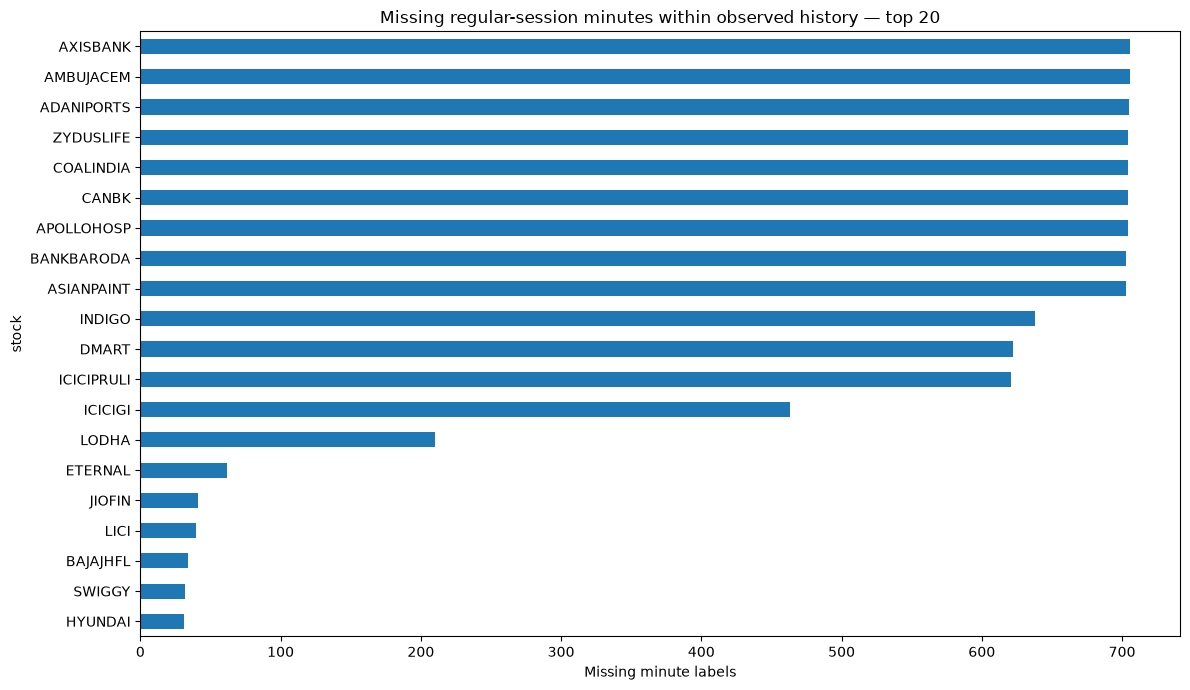

Saved session audit, inferred schedule, excluded dates, daily gaps, expected minute index, and sorted ranking to C:\Users\xprin\Desktop\AIML\BTP\full_predictor\eda_outputs


In [ ]:
ranking_rows, daily_missing_parts = [], []
for stock, observed in session_indices.items():
    present = expected_market_index.intersection(observed)
    if len(observed):
        start_day, end_day = observed.min().normalize(), observed.max().normalize()
        active_days = market_days[(market_days >= start_day) & (market_days <= end_day)]
        expected_days = market_schedule.loc[active_days, 'expected_minutes']
    else:
        start_day = end_day = pd.NaT
        active_days = pd.DatetimeIndex([])
        expected_days = pd.Series(dtype='int64')
    present_daily = pd.Series(1, index=present).groupby(present.normalize()).sum().reindex(active_days, fill_value=0)
    missing_daily = expected_days - present_daily
    expected_count, present_count = int(expected_days.sum()), int(present_daily.sum())
    missing_count = expected_count - present_count
    ranking_rows.append(dict(stock=stock, first_session_date=start_day, last_session_date=end_day,
        session_days_within_history=len(active_days), expected_minutes_within_history=expected_count,
        present_minutes_within_history=present_count, missing_minutes_within_history=missing_count,
        missing_pct_within_history=100*missing_count/expected_count if expected_count else np.nan,
        completely_missing_days=int(present_daily.eq(0).sum()),
        missing_minutes_outside_history=len(expected_market_index)-expected_count,
        missing_minutes_full_history=len(expected_market_index)-len(present),
        observed_minutes_outside_expected_schedule=len(observed.difference(expected_market_index))))
    daily_missing_parts.append(pd.DataFrame({'date':active_days, 'stock':stock,
        'expected_minutes':expected_days.to_numpy(), 'present_minutes':present_daily.to_numpy(),
        'missing_minutes':missing_daily.to_numpy()}))
missing_minute_ranking = pd.DataFrame(ranking_rows).sort_values(
    ['missing_minutes_within_history','stock'], ascending=[False,True]).reset_index(drop=True)
daily_missing_minutes = pd.concat(daily_missing_parts, ignore_index=True)
assert daily_missing_minutes.missing_minutes.ge(0).all()
assert (missing_minute_ranking.missing_minutes_full_history ==
        missing_minute_ranking.missing_minutes_within_history + missing_minute_ranking.missing_minutes_outside_history).all()
# Print every stock, already sorted descending, rather than a truncated notebook display.
print(missing_minute_ranking[['stock','missing_minutes_within_history','missing_pct_within_history',
    'completely_missing_days','missing_minutes_outside_history','missing_minutes_full_history']].to_string(index=False))
missing_minute_ranking.head(20).set_index('stock')['missing_minutes_within_history'].sort_values().plot.barh(
    figsize=(12,7), title='Missing regular-session minutes within observed history — top 20')
plt.xlabel('Missing minute labels'); plt.tight_layout(); plt.show()

# Example: inspect working OHLCV after removal of out-of-session rows.
# filtered_reliance = load_session_filtered_stock('RELIANCE')
# Missing labels for a chosen stock without creating a huge dense OHLCV table:
# missing_labels = expected_market_index.difference(session_indices['RELIANCE'])
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for name, table, include_index in [
    ('session_filter_audit.csv', session_filter_audit, True),
    ('market_session_schedule.csv', market_schedule, True),
    ('excluded_calendar_days.csv', excluded_calendar_days, False),
    ('missing_minute_ranking.csv', missing_minute_ranking, False),
    ('daily_missing_minutes.csv', daily_missing_minutes, False),
]:
    table.to_csv(OUTPUT_DIR/name, index=include_index)
pd.Series(expected_market_index, name='date').to_csv(OUTPUT_DIR/'expected_market_minutes.csv', index=False)
print('Saved session audit, inferred schedule, excluded dates, daily gaps, expected minute index, and sorted ranking to', OUTPUT_DIR.resolve())


## 6. Transform, add indicators, and validate

Missing bars are reindexed to the saved market-minute calendar and remain **NaN**. Raw files are preserved. The 97 retained stocks are processed one at a time and saved as Parquet, including warm-up rows and missingness flags.

Intraday indicators reset at session boundaries and missing/invalid bars. Features include SMA/EMA, RSI, Bollinger bands, trend/slope, returns/log returns, MACD, rolling volatility, and volume statistics. **GARCH is a daily volatility forecast** broadcast to valid minute rows, fitted monthly using earlier daily returns only. It is not a minute volatility estimate. Calibration periods remain NaN.

Features describe information available at each bar's close. Targets must be in the future. No scalers or future-data fills are applied. See [FEATURES.md](FEATURES.md) for formulas, units, warm-up and validation policy. Calendar assumptions from the preceding section still apply.


In [10]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display
FEATURE_BASE = Path.cwd() if (Path.cwd() / 'datasets').is_dir() else Path.cwd() / 'full_predictor'
if str(FEATURE_BASE.resolve()) not in sys.path:
    sys.path.insert(0, str(FEATURE_BASE.resolve()))
from feature_engineering import transform_all
# Requires arch and pyarrow in the notebook kernel environment.
# Uses the saved expected_market_minutes.csv; rerun session coverage first if calendar rules change.
REBUILD_FEATURE_DATA = False  # Set True after changing sources, calendar, or feature definitions.
validation_path = FEATURE_BASE / 'processed_datasets' / 'feature_validation.csv'
if REBUILD_FEATURE_DATA or not validation_path.exists():
    feature_validation = transform_all(FEATURE_BASE)
else:
    feature_validation = pd.read_csv(validation_path)
    print('Loaded existing validated feature datasets; set REBUILD_FEATURE_DATA=True to rebuild.')
display(feature_validation)
print('Validated stocks:', len(feature_validation))
print('Preserved missing bars:', int(feature_validation.missing_bars.sum()))
print('Saved to:', (FEATURE_BASE / 'processed_datasets' / 'NIFTY50').resolve())


Loaded existing validated feature datasets; set REBUILD_FEATURE_DATA=True to rebuild.
Validated stocks: 97
Preserved missing bars: 102724
Saved to: C:\Users\xprin\Desktop\AIML\BTP\full_predictor\processed_datasets\NIFTY50


,stock,raw_rows,aligned_rows,excluded_timestamp_rows,missing_bars,invalid_observed_bars,feature_count,complete_feature_rows,garch_populated_rows,output_bytes,validation
0,ABB,970889,972585,710,2406,0,35,582294,916974,190947863,passed
1,ADANIENSOL,919752,926085,685,7018,0,35,523250,872652,169912447,passed
2,ADANIENT,972518,972585,697,764,0,35,666066,910358,199228981,passed
3,ADANIGREEN,659285,660585,475,1775,0,35,391473,608964,128569354,passed
4,ADANIPORTS,972581,972585,701,705,0,35,674228,918667,197271639,passed
5,ADANIPOWER,972537,972585,673,721,0,35,653513,918651,180399409,passed
6,AMBUJACEM,972579,972585,700,706,0,35,673486,918666,189927054,passed
7,APOLLOHOSP,972578,972585,697,704,0,35,664012,910043,203789474,passed
8,ASIANPAINT,972584,972585,702,703,0,35,674217,918669,204041349,passed
9,AXISBANK,972579,972585,700,706,0,35,674253,918666,200633859,passed


GARCH fit outcomes:
NaNs are intentional: missing/invalid bars, indicator warm-up, zero denominators, or GARCH calibration/unavailable fits.


,nan_count,finite_count,nan_on_valid_bars
feature,,,
bb_lower_20,4859021,82539844,4738575
bb_middle_20,4859021,82539844,4738575
bb_position_20,5079036,82319829,4958590
bb_upper_20,4859021,82539844,4738575
bb_width_20,4859021,82539844,4738575
dollar_volume,120446,87278419,0
ema_10,2412883,84985982,2292437
ema_100,23826517,63572348,23706071
ema_20,4859021,82539844,4738575


status
ok        10740
failed        9
Name: count, dtype: int64

,open,high,low,close,volume,is_missing_bar,is_valid_bar,segment_id,returns,log_returns,sma_5,ema_5,sma_10,ema_10,sma_20,ema_20,sma_50,ema_50,sma_100,ema_100,rsi_14,bb_middle_20,bb_upper_20,bb_lower_20,bb_width_20,bb_position_20,trend,trend_strength,trend_slope_20,trend_slope_pct_20,macd,macd_signal,macd_histogram,rolling_volatility_30,volume_sma_20,relative_volume_20,volume_zscore_20,volume_change,log_volume,dollar_volume,obv_segment,vwap_segment,garch_daily_volatility
date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2015-02-02 09:15:00,216.45,217.15,216.30,216.40,229342.0,False,True,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.342974,49629608.8,0.0,216.616667,NaN
2015-02-02 09:16:00,216.40,216.55,216.00,216.00,97732.0,False,True,1,-0.001848,-0.001850,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.573859,11.489995,21110112.0,-97732.0,216.487184,NaN
2015-02-02 09:17:00,216.00,216.40,215.95,216.20,103552.0,False,True,1,0.000926,0.000925,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.059551,11.547839,22387942.4,5820.0,216.414117,NaN
2015-02-02 09:18:00,216.30,216.80,216.30,216.60,119870.0,False,True,1,0.001850,0.001848,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.157583,11.694171,25963842.0,125690.0,216.447335,NaN
2015-02-02 09:19:00,216.60,216.60,216.35,216.45,67104.0,False,True,1,-0.000693,-0.000693,216.33,216.391975,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.440194,11.114014,14524660.8,58586.0,216.449435,NaN


,open,high,low,close,volume,is_missing_bar,is_valid_bar,segment_id,returns,log_returns,sma_5,ema_5,sma_10,ema_10,sma_20,ema_20,sma_50,ema_50,sma_100,ema_100,rsi_14,bb_middle_20,bb_upper_20,bb_lower_20,bb_width_20,bb_position_20,trend,trend_strength,trend_slope_20,trend_slope_pct_20,macd,macd_signal,macd_histogram,rolling_volatility_30,volume_sma_20,relative_volume_20,volume_zscore_20,volume_change,log_volume,dollar_volume,obv_segment,vwap_segment,garch_daily_volatility
date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2015-03-13 09:27:00,NaN,NaN,NaN,NaN,NaN,True,False,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-03-13 09:30:00,NaN,NaN,NaN,NaN,NaN,True,False,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-03-13 09:31:00,NaN,NaN,NaN,NaN,NaN,True,False,33,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-03-13 09:33:00,NaN,NaN,NaN,NaN,NaN,True,False,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-03-13 09:35:00,NaN,NaN,NaN,NaN,NaN,True,False,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


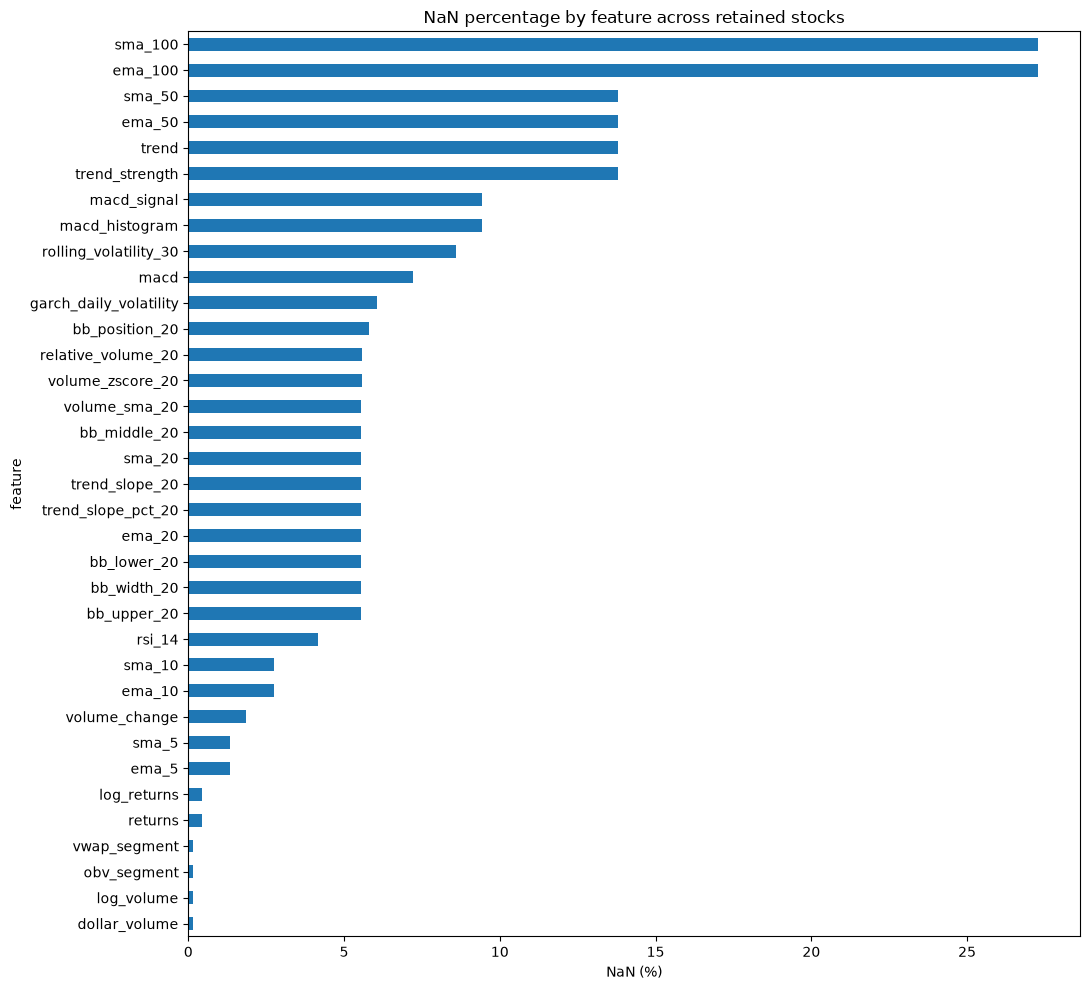

In [11]:
feature_nan_report = pd.read_csv(FEATURE_BASE / 'processed_datasets' / 'feature_nan_report.csv')
garch_fit_audit = pd.read_csv(FEATURE_BASE / 'processed_datasets' / 'garch_fit_audit.csv')
display(feature_nan_report.groupby('feature')[['nan_count','finite_count','nan_on_valid_bars']].sum())
print('GARCH fit outcomes:')
display(garch_fit_audit['status'].value_counts())
example_features = pd.read_parquet(FEATURE_BASE / 'processed_datasets' / 'NIFTY50' / 'RELIANCE.parquet')
display(example_features.head())
display(example_features.loc[example_features.is_missing_bar].head())
print('NaNs are intentional: missing/invalid bars, indicator warm-up, zero denominators, or GARCH calibration/unavailable fits.')

# Per-feature availability: NaNs stay in the saved data.
import matplotlib.pyplot as plt
availability = feature_nan_report.groupby('feature')[['nan_count','finite_count']].sum()
(100 * availability.nan_count / availability.sum(axis=1)).sort_values().plot.barh(
    figsize=(11, 10), title='NaN percentage by feature across retained stocks')
plt.xlabel('NaN (%)'); plt.tight_layout(); plt.show()
